In [2]:
!pip install pandas matplotlib

--- RUNNING GEOGRAPHIC TO UTM COORDINATE CONVERSION ---
Point_ID  Latitude  Longitude  UTM_Easting_m  UTM_Northing_m  UTM_Zone Hemisphere
     P01    0.3476    32.5825     453543.138       38421.276        36          N
     P02    0.3521    32.5890     454266.453       38918.642        36          N
     P03    0.3589    32.5955     454989.778       39670.234        36          N
     P04    0.3610    32.6010     455601.804       39902.326        36          N


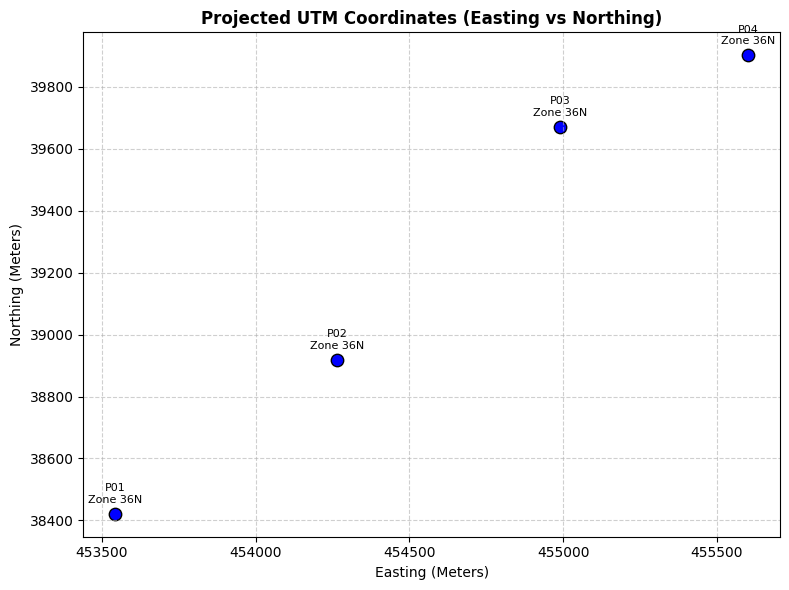

In [3]:
import math
import pandas as pd
import matplotlib.pyplot as plt

class LatLongToUTMConverter:
    def __init__(self, a=6378137.0, f=1/298.257223563):
        """Initializes WGS84 Ellipsoid Constants."""
        self.a = a  # Semi-major axis
        self.f = f  # Flattening
        self.b = a * (1 - f)  # Semi-minor axis
        self.e2 = (a**2 - self.b**2) / (a**2)  # First eccentricity squared
        self.e_prime2 = (a**2 - self.b**2) / (self.b**2)  # Second eccentricity squared
        self.k0 = 0.9996  # Central scale factor for UTM

    def get_utm_zone(self, longitude: float) -> int:
        """Determines UTM Zone (1 to 60) from Longitude."""
        return int((longitude + 180) / 6) + 1

    def convert_point(self, lat: float, lon: float):
        """
        Converts a single (Lat, Long) pair in decimal degrees to UTM (Easting, Northing, Zone, Hemisphere).
        Uses standard Transverse Mercator (Redfearn's Series) projection logic.
        """
        zone = self.get_utm_zone(lon)
        lon_origin = (zone - 1) * 6 - 180 + 3  # Central meridian of the zone

        lat_rad = math.radians(lat)
        lon_rad = math.radians(lon)
        lon_origin_rad = math.radians(lon_origin)

        N = self.a / math.sqrt(1 - self.e2 * (math.sin(lat_rad)**2))
        T = math.tan(lat_rad)**2
        C = self.e_prime2 * (math.cos(lat_rad)**2)
        A = (lon_rad - lon_origin_rad) * math.cos(lat_rad)

        # Meridional Distance (M) computation
        M = self.a * (
            (1 - self.e2/4 - 3*self.e2**2/64 - 5*self.e2**3/256) * lat_rad
            - (3*self.e2/8 + 3*self.e2**2/32 + 45*self.e2**3/1024) * math.sin(2*lat_rad)
            + (15*self.e2**2/256 + 45*self.e2**3/1024) * math.sin(4*lat_rad)
            - (35*self.e2**3/3072) * math.sin(6*lat_rad)
        )

        # Calculate Easting (E)
        easting = self.k0 * N * (
            A + (1 - T + C) * (A**3)/6
            + (5 - 18*T + T**2 + 72*C - 58*self.e_prime2) * (A**5)/120
        ) + 500000.0  # False Easting

        # Calculate Northing (N)
        northing = self.k0 * (
            M + N * math.tan(lat_rad) * (
                (A**2)/2
                + (5 - T + 9*C + 4*(C**2)) * (A**4)/24
                + (61 - 58*T + T**2 + 600*C - 330*self.e_prime2) * (A**6)/720
            )
        )

        hemisphere = 'N'
        if lat < 0:
            northing += 10000000.0  # False Northing for Southern Hemisphere
            hemisphere = 'S'

        return round(easting, 3), round(northing, 3), zone, hemisphere

    def process_dataframe(self, df: pd.DataFrame) -> pd.DataFrame:
        """Batch processing of a pandas DataFrame with Point_ID, Latitude, Longitude."""
        eastings, northings, zones, hemispheres = [], [], [], []

        for _, row in df.iterrows():
            e, n, z, h = self.convert_point(row['Latitude'], row['Longitude'])
            eastings.append(e)
            northings.append(n)
            zones.append(z)
            hemispheres.append(h)

        df_res = df.copy()
        df_res['UTM_Easting_m'] = eastings
        df_res['UTM_Northing_m'] = northings
        df_res['UTM_Zone'] = zones
        df_res['Hemisphere'] = hemispheres
        return df_res


def plot_utm_points(df_utm: pd.DataFrame):
    """Plots projected UTM Easting and Northing coordinates."""
    plt.figure(figsize=(8, 6))
    plt.scatter(df_utm['UTM_Easting_m'], df_utm['UTM_Northing_m'], c='blue', marker='o', s=80, edgecolors='black')

    for _, row in df_utm.iterrows():
        plt.annotate(f"{row['Point_ID']}\nZone {row['UTM_Zone']}{row['Hemisphere']}",
                     (row['UTM_Easting_m'], row['UTM_Northing_m']),
                     textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)

    plt.title("Projected UTM Coordinates (Easting vs Northing)", fontsize=12, fontweight='bold')
    plt.xlabel("Easting (Meters)")
    plt.ylabel("Northing (Meters)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.ticklabel_format(useOffset=False, style='plain')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    converter = LatLongToUTMConverter()

    sample_data = pd.DataFrame({
        'Point_ID': ['P01', 'P02', 'P03', 'P04'],
        'Latitude': [0.3476, 0.3521, 0.3589, 0.3610],
        'Longitude': [32.5825, 32.5890, 32.5955, 32.6010]
    })

    print("--- RUNNING GEOGRAPHIC TO UTM COORDINATE CONVERSION ---")
    results_df = converter.process_dataframe(sample_data)
    print(results_df.to_string(index=False))
    plot_utm_points(results_df)
